In [ ]:
%pip install pybis
%pip install requests
%pip install python-dotenv #for secure credentials
%pip install zipfile

In [ ]:
from pybis import Openbis
o = Openbis("https://playground.datastore.bam.de/")

o.set_token("your_token_here")

In [ ]:
space = o.get_space('X.1_MATERIALS')
space.get_projects()

Proj = SAMPLES_SYNTHESIS

Collection = Samples

In [ ]:
proj = next((p for p in space.get_projects() if p.attrs.all()['code'] == 'SAMPLES_SYNTHESIS'))
proj.attrs.all()

In [ ]:
col = next((c for c in proj.get_collections() if c.props.all()['$name'] == 'Samples'))
col.props.all()

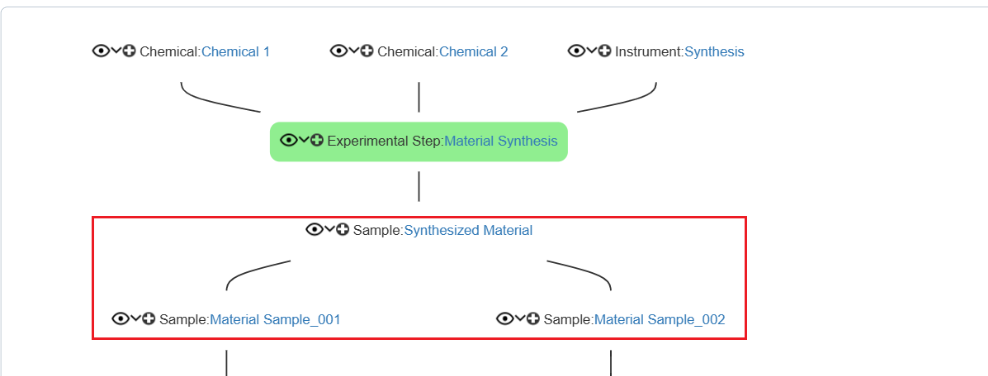

Then we need Synthesized Material because we are going to be connecting it as a child to the experimental step Material Synthesis

In [ ]:
synthesized_sample = next((s for s in col.get_samples() if s.props.all()['$name'] == 'Synthesized Material'))

synthesized_sample_identifier = synthesized_sample.attrs.all()['identifier']

synthesized_sample_identifier

# We need the identifier of the sample to be used in the connect data tutorial. The identifier can be obtained from the synthesized_sample object.

now that we have the code for the child, we need to get the parent, which is material synthesis -> synthesis, for me its MATERIAL_SYNTHESIS_PYBIS2 -> synthesis

In [ ]:
o.get_spaces()
myspace = o.get_space('your_space_code_here')

In [ ]:
myproj = next((p for p in myspace.get_projects() if p.attrs.all()['code'] == 'MATERIAL_SYNTHESIS'))
myproj

Then we will find material synthesis which is a sample in synthesis

In [ ]:
mycol = next((c for c in myproj.get_collections() if c.props.all()['$name'] == 'Synthesis'))
mycol.props.all()

In [ ]:
mysample = next((s for s in mycol.get_samples() if s.props.all()['$name'] == 'Material Synthesis'))
mysample.props.all()

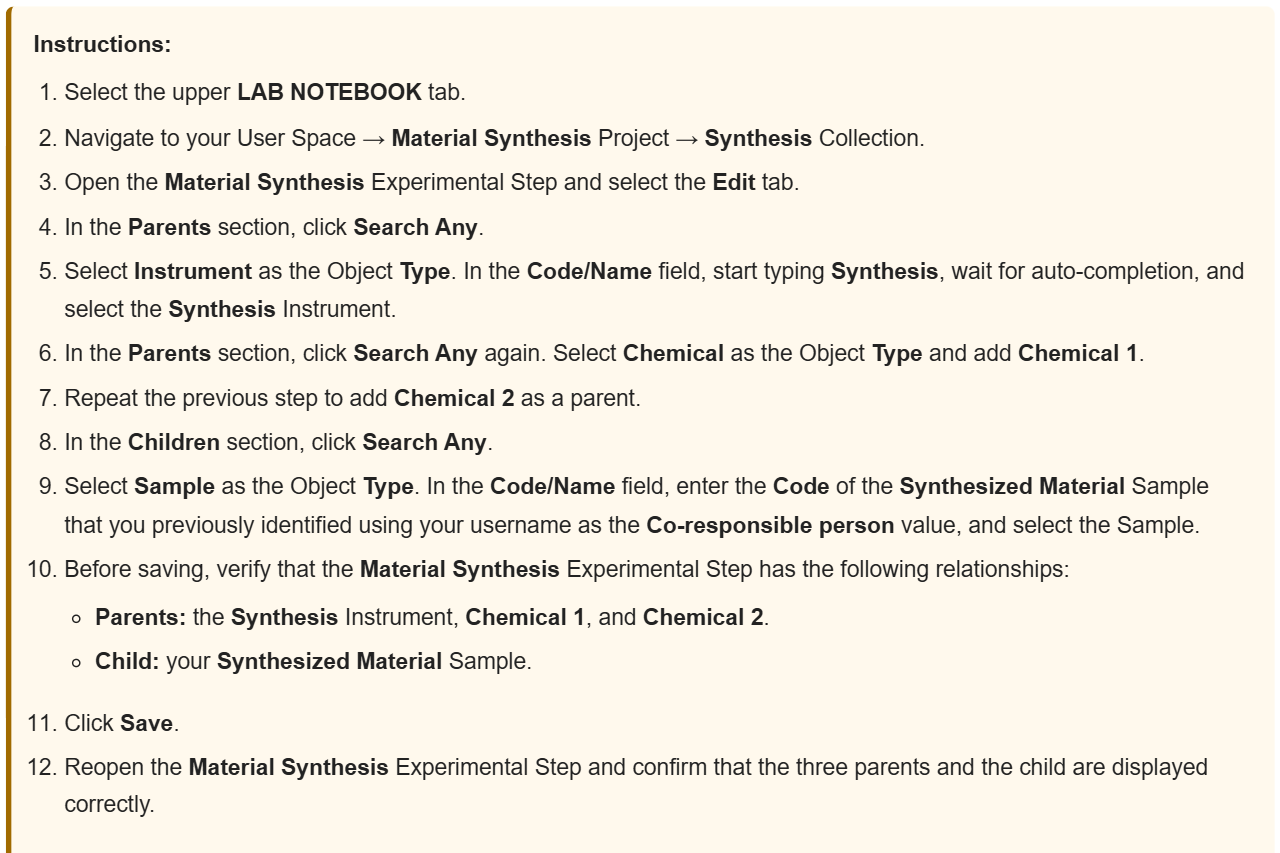

In [ ]:
mysample.get_parents()#this should display nothing because the sample has no parents yet, we will add a parent in the next step

We need to find the indentifiers for chemical 1, chemical 2, and the synthesis instrument.

In [ ]:
parent_chemicals_space = o.get_space('X.1_MATERIALS')
parent_chemicals_proj = next((p for p in parent_chemicals_space.get_projects() if p.attrs.all()['code'] == 'CHEMICALS_SYNTHESIS'))
parent_chemicals_collection = next((c for c in parent_chemicals_proj.get_collections() if c.props.all()['$name'] == 'Chemicals'))
parent_chemicals_samples = parent_chemicals_collection.get_samples()
parent_chemicals_samples_identifiers = [s.attrs.all()['identifier'] for s in parent_chemicals_samples if s.props.all()['$name'] in ['Chemical 1', 'Chemical 2']]
parent_chemicals_samples_identifiers

In [ ]:
parents_synthesis_space = o.get_space('BAM_EQUIPMENT')
parents_synthesis_proj = next((p for p in parents_synthesis_space.get_projects() if p.attrs.all()['code'] == 'X.1_EQUIPMENT_OPEN'))
parents_synthesis_collection = next((c for c in parents_synthesis_proj.get_collections() if c.props.all()['$name'] == 'Instruments'))
parents_synthesis_samples = parents_synthesis_collection.get_samples()
parents_synthesis_samples_identifiers = [s.attrs.all()['identifier'] for s in parents_synthesis_samples if s.props.all()['$name'] == 'Synthesis']
parents_synthesis_samples_identifiers

In [ ]:
mysample.set_parents([parent_chemicals_samples_identifiers[0], parent_chemicals_samples_identifiers[1], parents_synthesis_samples_identifiers[0]])#this will add the parents to the sample, we can add more parents if we want to, but for now we will just add these two parents
mysample.save()

In [ ]:
mysample.get_parents()

In [ ]:
mysample.get_children()#this should display nothing because the sample has no children yet, we will add a child in the next step

In [ ]:
# Need to store it again because there are errors that are not explainable
mysample = next((s for s in mycol.get_samples() if s.props.all()['$name'] == 'Material Synthesis'))

In [ ]:
mysample.set_children([synthesized_sample_identifier])
mysample.save()

In [ ]:
mysample.get_children()

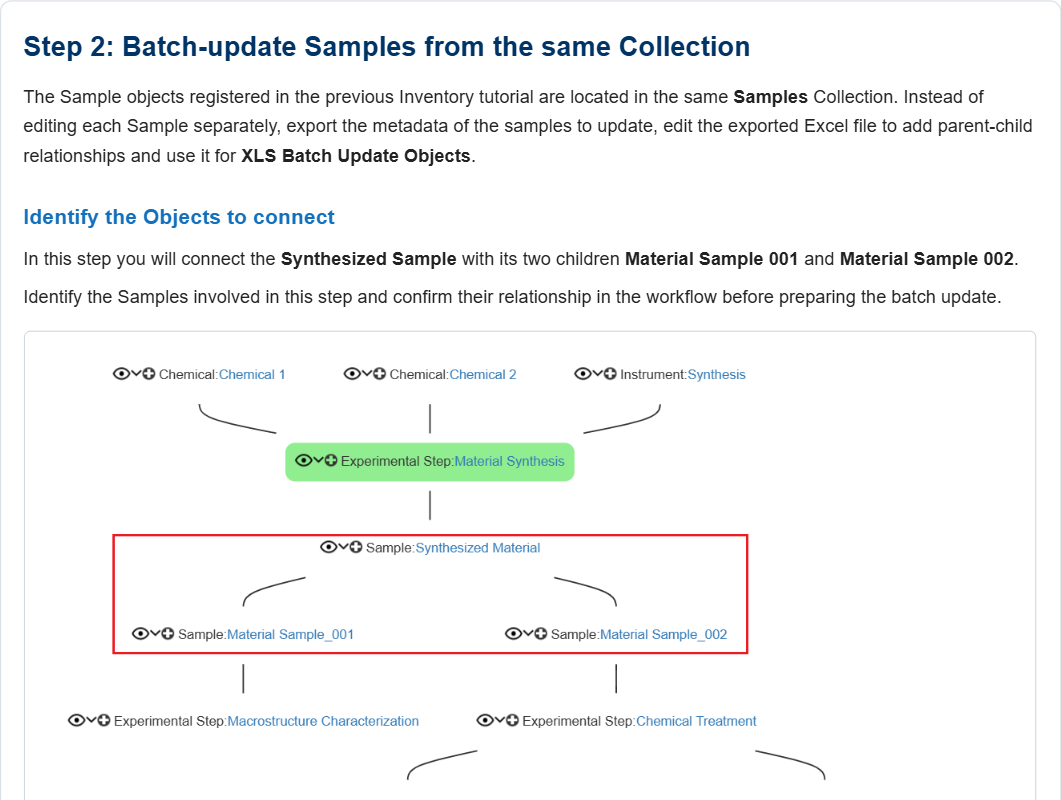

We will be adding the relationships between Synthesized Material, Material Sample_001 and Material Sample_002

In [ ]:
synthesized_sample.props.all()

We find and save Material Sample 001 and 002 for later use

In [ ]:
proj = next((p for p in space.get_projects() if p.attrs.all()['code'] == 'SAMPLES_SYNTHESIS'))
col = next((c for c in proj.get_collections() if c.props.all()['$name'] == 'Samples'))
ms_001 = next((s for s in col.get_samples() if s.props.all()['$name'] == 'Material Sample_001'))
ms_002 = next((s for s in col.get_samples() if s.props.all()['$name'] == 'Material Sample_002'))
# ms_001.props.all()
# ms_002.props.all()

In [ ]:
ms_001.set_parents([synthesized_sample.identifier])
ms_001.save()
ms_002.set_parents([synthesized_sample.identifier])
ms_002.save()

synthesized_sample.set_children([ms_001.identifier, ms_002.identifier])
synthesized_sample.save()

Next, we add the relationship between Material Sample_001 and Macrostructure Characterization

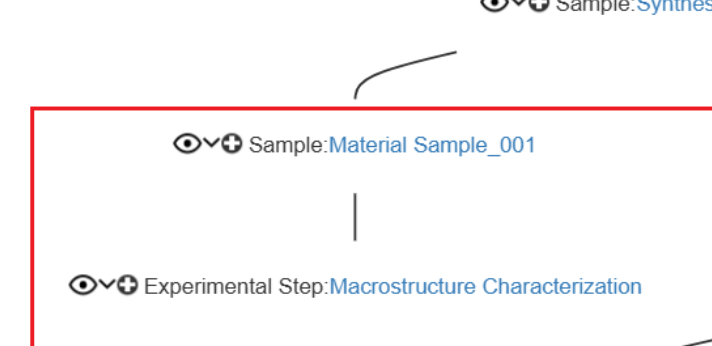

In [ ]:
mycol = next((c for c in myproj.get_collections() if c.props.all()['$name'] == 'Parameter 1')) #macrostructure characterization is in the parameter 1 collection
mycol.props.all()

In [ ]:
macro = next((s for s in mycol.get_samples() if s.props.all()['$name'] == 'Macrostructure Characterization'))
macro.props.all()

In [ ]:
ms_001.props.all()

In [ ]:
ms_001.set_children([macro.identifier])
ms_001.save()
macro.set_parents([ms_001.identifier])
macro.save()

Next, we add the relationship between Material Sample_002 and Chemical Treatment

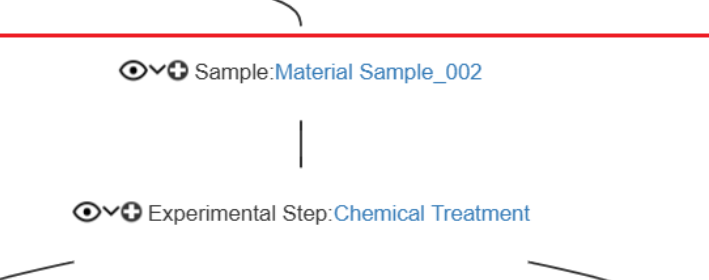

In [ ]:
mycol = next((c for c in myproj.get_collections() if c.props.all()['$name'] == 'Treatment non-destructive')) #Chemical Treatment is in the Treatment non-destructive collection
mycol.props.all()

In [ ]:
chem = next((s for s in mycol.get_samples() if s.props.all()['$name'] == 'Chemical Treatment'))
chem.props.all()

In [ ]:
ms_002.props.all()

In [ ]:
ms_002.set_children([chem.identifier])
ms_002.save()
chem.set_parents([ms_002.identifier])
chem.save()

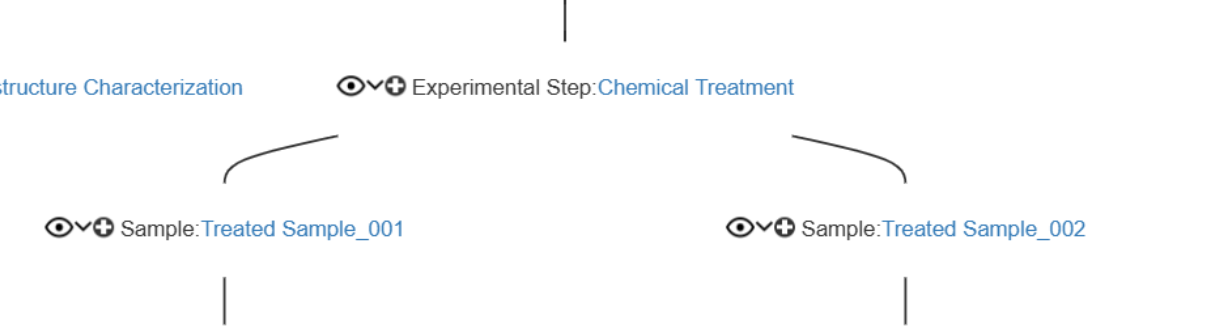

Then, we connect Chemical Treatment with Treated Sample_001 and Treated Sample_002

In [ ]:
chem.props.all()

In [ ]:
proj = next((p for p in space.get_projects() if p.attrs.all()['code'] == 'SAMPLES_SYNTHESIS'))
col = next((c for c in proj.get_collections() if c.props.all()['$name'] == 'Samples'))
tr_001 = next((s for s in col.get_samples() if s.props.all()['$name'] == 'Treated Sample_001'))
tr_002 = next((s for s in col.get_samples() if s.props.all()['$name'] == 'Treated Sample_002'))
# tr_001.props.all()
# tr_002.props.all()

In [ ]:
chem.set_children([tr_001.identifier, tr_002.identifier])
chem.save()
tr_001.set_parents([chem.identifier])
tr_001.save()
tr_002.set_parents([chem.identifier])
tr_002.save()

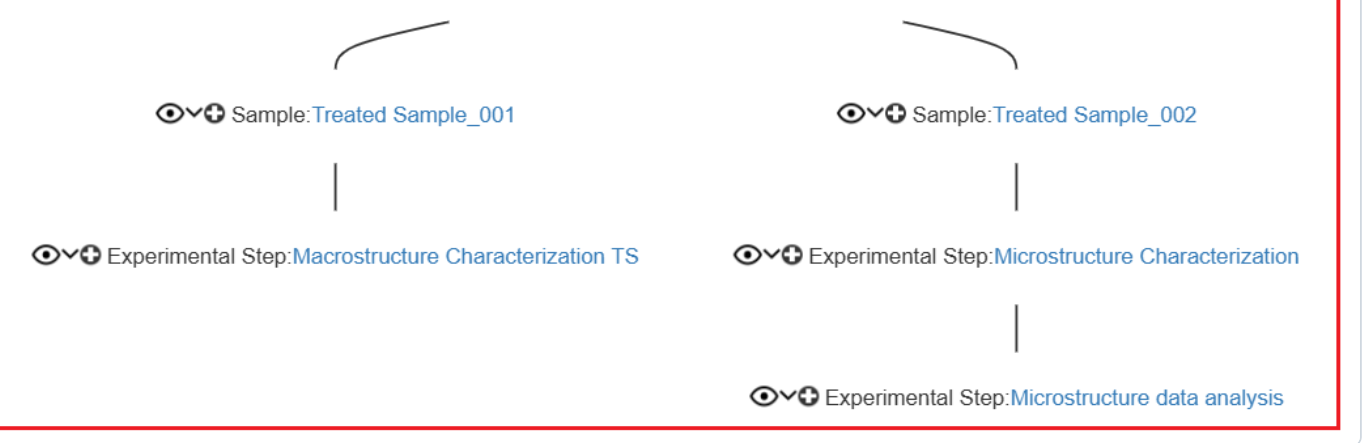

Then we have to connect Treated Sample_001 with Macrostructure Characterization TS

In [ ]:
mycol = next((c for c in myproj.get_collections() if c.props.all()['$name'] == 'Parameter 1'))#Macrostructure Characterization TS  is a sample in the Parameter 1 collection
mycol.props.all()

In [ ]:
macro_ts = next((s for s in mycol.get_samples() if s.props.all()['$name'] == 'Macrostructure Characterization TS'))
macro_ts.props.all()

In [ ]:
# we already have Treated Sample_001 saved in tr_001 variable so we reuse it

tr_001.set_children([macro_ts.identifier])
tr_001.save()
macro_ts.set_parents([tr_001.identifier])
macro_ts.save()

Then we connect Treated Sample_002 with Microstructure Characterization


In [ ]:
mycol = next((c for c in myproj.get_collections() if c.props.all()['$name'] == 'Parameter 2'))#Microstructure Characterization is a sample in the Parameter 2 collection
mycol.props.all()

In [ ]:
micro = next((s for s in mycol.get_samples() if s.props.all()['$name'] == 'Microstructure Characterization'))
micro.props.all()

In [ ]:
# we already have Treated Sample_002 saved in tr_002 variable so we reuse it

tr_002.set_children([micro.identifier])
tr_002.save()
micro.set_parents([tr_002.identifier])
micro.save()

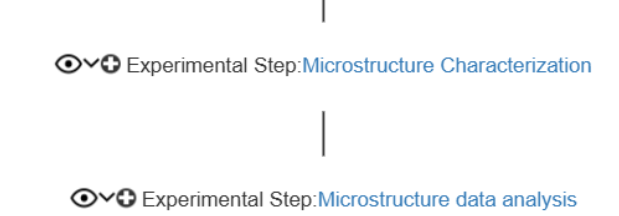

Then we have to connect Microstructure Characterization with Microstructure data analysis

In [ ]:
mycol = next((c for c in myproj.get_collections() if c.props.all()['$name'] == 'Parameter 2 Analysis'))#Microstructure data analysis is a sample in the Parameter 2 Analysis collection
mycol.props.all()

In [ ]:
micro_da = next((s for s in mycol.get_samples() if s.props.all()['$name'] == 'Microstructure data analysis'))
micro_da.props.all()

In [ ]:
# we already have Microstructure Characterization saved in micro variable so we reuse it
micro.set_children([micro_da.identifier])
micro.save()
micro_da.set_parents([micro.identifier])
micro_da.save()

# Connecting instruments and chemicals to samples

### In this step, we make these connections

| Parent              | Child                              |
|---------------------|------------------------------------|
| Macrostructure      | Macrostructure Characterization    |
| Macrostructure      | Macrostructure Characterization TS |
| Treatment Solution  | Chemical Treatment                 |
| Microstructure      | Microstructure Characterization    |


We first connect Macrostructure with Macrostructure Characterization and Macrostructure Characterization TS

Note, when adding more parents to a sample that already has parent(s), use add_parents because set_parents overwrites the previous parents and may result in a loss of previously connected relationships, same with set_children, use add_children

In [ ]:
# We start by finding and storing Macrostructure

macrostructure_space = o.get_space('BAM_EQUIPMENT')
macrostructure_proj = next((p for p in macrostructure_space.get_projects() if p.attrs.all()['code'] == 'X.1_EQUIPMENT_OPEN'))
macrostructure_collection = next((c for c in macrostructure_proj.get_collections() if c.props.all()['$name'] == 'Instruments'))

macrostructure_sample = next((s for s in macrostructure_collection.get_samples() if s.props.all()['$name'] == 'Macrostructure'))
macrostructure_sample.props.all()

In [ ]:
macro.add_parents([macrostructure_sample.identifier])
macro.save()
macro_ts.add_parents([macrostructure_sample.identifier])
macro_ts.save()

macrostructure_sample.add_children([macro.identifier, macro_ts.identifier])
macrostructure_sample.save()

In [ ]:
macrostructure_sample.get_children()

Then we will connect Treatment Solution and Chemical Treatment  

In [ ]:
treatment_solution_space = o.get_space('X.1_MATERIALS')
treatment_solution_proj = next((p for p in treatment_solution_space.get_projects() if p.attrs.all()['code'] == 'CHEMICALS_SYNTHESIS'))
treatment_solution_collection = next((c for c in treatment_solution_proj.get_collections() if c.props.all()['$name'] == 'Chemicals'))
treatment_solution = next((s for s in treatment_solution_collection.get_samples() if s.props.all()['$name'] == 'Treatment Solution'))
treatment_solution.props.all()

In [ ]:
chem.props.all()

In [ ]:
chem.add_parents([treatment_solution.identifier])
chem.save()

treatment_solution.add_children([chem.identifier])
treatment_solution.save()

In [ ]:
treatment_solution.get_children()

Then we will connect Microstructure and Microstructure Characterization

In [ ]:
# We start by finding and storing Microstructure

microstructure_space = o.get_space('BAM_EQUIPMENT')
microstructure_proj = next((p for p in microstructure_space.get_projects() if p.attrs.all()['code'] == 'X.1_EQUIPMENT_OPEN'))
microstructure_collection = next((c for c in microstructure_proj.get_collections() if c.props.all()['$name'] == 'Instruments'))

microstructure_sample = next((s for s in microstructure_collection.get_samples() if s.props.all()['$name'] == 'Microstructure'))
microstructure_sample.props.all()

In [ ]:
micro.props.all()

In [ ]:
micro.add_parents([microstructure_sample.identifier])
micro.save()

microstructure_sample.add_children([micro.identifier])
microstructure_sample.save()

In [ ]:
microstructure_sample.get_children()